# Which teams dominated each era of F1?

Metric: percentage of races won by each team per season.
Data: F1DB (CC BY 4.0), up to the 2026 Brazilian Grand Prix.

In [1]:
import pandas as pd

In [2]:
results = pd.read_csv("../data/raw/f1db/f1db-races-race-results.csv", low_memory=False)

In [3]:
results.head()

,raceId,year,round,positionDisplayOrder,positionNumber,positionText,driverNumber,driverId,constructorId,engineManufacturerId,...,polePosition,qualificationPositionNumber,qualificationPositionText,gridPositionNumber,gridPositionText,positionsGained,pitStops,fastestLap,driverOfTheDay,grandSlam
0,1,1950,1,1,1.0,1,2,nino-farina,alfa-romeo,alfa-romeo,...,True,1.0,1,1.0,1,0.0,NaN,True,NaN,False
1,1,1950,1,2,2.0,2,3,luigi-fagioli,alfa-romeo,alfa-romeo,...,False,2.0,2,2.0,2,0.0,NaN,False,NaN,False
2,1,1950,1,3,3.0,3,4,reg-parnell,alfa-romeo,alfa-romeo,...,False,4.0,4,4.0,4,1.0,NaN,False,NaN,False
3,1,1950,1,4,4.0,4,14,yves-giraud-cabantous,talbot-lago,talbot-lago,...,False,6.0,6,6.0,6,2.0,NaN,False,NaN,False
4,1,1950,1,5,5.0,5,15,louis-rosier,talbot-lago,talbot-lago,...,False,9.0,9,9.0,9,4.0,NaN,False,NaN,False


In [4]:
results.columns

Index(['raceId', 'year', 'round', 'positionDisplayOrder', 'positionNumber',
       'positionText', 'driverNumber', 'driverId', 'constructorId',
       'engineManufacturerId', 'tyreManufacturerId', 'sharedCar', 'laps',
       'time', 'timeMillis', 'timePenalty', 'timePenaltyMillis', 'gap',
       'gapMillis', 'gapLaps', 'interval', 'intervalMillis', 'reasonRetired',
       'points', 'polePosition', 'qualificationPositionNumber',
       'qualificationPositionText', 'gridPositionNumber', 'gridPositionText',
       'positionsGained', 'pitStops', 'fastestLap', 'driverOfTheDay',
       'grandSlam'],
      dtype='str')

In [5]:
results["positionText"].value_counts()

positionText
DNF     8796
3       1179
4       1179
2       1177
5       1175
1       1172
6       1168
7       1152
8       1123
9       1083
DNQ     1041
10      1023
11       949
12       849
13       756
14       657
15       574
16       476
DNS      382
17       376
DNPQ     338
18       261
NC       200
19       167
DSQ      161
20        89
21        40
22        28
23        20
EX        15
24        14
25        14
27        12
28        12
30        12
31        12
26        11
29        11
32        11
33        11
DNP        5
Name: count, dtype: int64

In [6]:
results["raceId"].nunique()

1169

In [7]:
winners = results[results["positionNumber"] == 1]

In [8]:
winners[winners["sharedCar"] == True]

,raceId,year,round,positionDisplayOrder,positionNumber,positionText,driverNumber,driverId,constructorId,engineManufacturerId,...,polePosition,qualificationPositionNumber,qualificationPositionText,gridPositionNumber,gridPositionText,positionsGained,pitStops,fastestLap,driverOfTheDay,grandSlam
231,11,1951,4,2,1.0,1,8,juan-manuel-fangio,alfa-romeo,alfa-romeo,...,False,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,False
1231,49,1956,1,2,1.0,1,34,juan-manuel-fangio,ferrari,ferrari,...,False,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,False
1513,61,1957,5,2,1.0,1,20,stirling-moss,vanwall,vanwall,...,False,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,False


In [9]:
winners[winners["raceId"].isin([11, 49, 61])]

,raceId,year,round,positionDisplayOrder,positionNumber,positionText,driverNumber,driverId,constructorId,engineManufacturerId,...,polePosition,qualificationPositionNumber,qualificationPositionText,gridPositionNumber,gridPositionText,positionsGained,pitStops,fastestLap,driverOfTheDay,grandSlam
230,11,1951,4,1,1.0,1,8,luigi-fagioli,alfa-romeo,alfa-romeo,...,False,7.0,7,7.0,7,6.0,NaN,False,NaN,False
231,11,1951,4,2,1.0,1,8,juan-manuel-fangio,alfa-romeo,alfa-romeo,...,False,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,False
1230,49,1956,1,1,1.0,1,34,luigi-musso,ferrari,ferrari,...,False,3.0,3,3.0,3,2.0,NaN,False,NaN,False
1231,49,1956,1,2,1.0,1,34,juan-manuel-fangio,ferrari,ferrari,...,False,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,False
1512,61,1957,5,1,1.0,1,20,tony-brooks,vanwall,vanwall,...,False,3.0,3,3.0,3,2.0,NaN,False,NaN,False
1513,61,1957,5,2,1.0,1,20,stirling-moss,vanwall,vanwall,...,False,NaN,NaN,NaN,NaN,NaN,NaN,True,NaN,False


In [10]:
race_wins = winners.drop_duplicates(subset="raceId")

In [11]:
len(race_wins)

1169

In [12]:
races = pd.read_csv("../data/raw/f1db/f1db-races.csv")
races.columns

Index(['id', 'year', 'round', 'date', 'time', 'grandPrixId', 'officialName',
       'qualifyingFormat', 'sprintQualifyingFormat', 'circuitId',
       'circuitLayoutId', 'circuitType', 'direction', 'courseLength', 'turns',
       'laps', 'distance', 'scheduledLaps', 'scheduledDistance',
       'driversChampionshipDecider', 'constructorsChampionshipDecider',
       'preQualifyingDate', 'preQualifyingTime', 'freePractice1Date',
       'freePractice1Time', 'freePractice2Date', 'freePractice2Time',
       'freePractice3Date', 'freePractice3Time', 'freePractice4Date',
       'freePractice4Time', 'qualifying1Date', 'qualifying1Time',
       'qualifying2Date', 'qualifying2Time', 'qualifyingDate',
       'qualifyingTime', 'sprintQualifyingDate', 'sprintQualifyingTime',
       'sprintRaceDate', 'sprintRaceTime', 'sprintRaceLaps',
       'sprintRaceDistance', 'sprintRaceScheduledLaps',
       'sprintRaceScheduledDistance', 'warmingUpDate', 'warmingUpTime'],
      dtype='str')

In [13]:
indy_ids = races[races["grandPrixId"] == "indianapolis"]["id"]
race_wins = race_wins[~race_wins["raceId"].isin(indy_ids)]
len(race_wins)

1158

In [14]:
team_wins = race_wins.groupby(["year", "constructorId"]).size().reset_index(name="wins")

In [15]:
team_wins[team_wins["year"] == 1988]

,year,constructorId,wins
145,1988,ferrari,1
146,1988,mclaren,15


In [16]:
races_per_year = race_wins.groupby("year").size().reset_index(name="races")
races_per_year.tail()

,year,races
72,2022,22
73,2023,22
74,2024,24
75,2025,24
76,2026,20


In [17]:
team_wins = team_wins.merge(races_per_year, on="year")

In [18]:
team_wins["win_pct"] = team_wins["wins"] / team_wins["races"] * 100
team_wins.head()

,year,constructorId,wins,races,win_pct
0,1950,alfa-romeo,6,6,100.000000
1,1951,alfa-romeo,4,7,57.142857
2,1951,ferrari,3,7,42.857143
3,1952,ferrari,7,7,100.000000
4,1953,ferrari,7,8,87.500000


In [19]:
team_wins[team_wins["year"] == 1988]

,year,constructorId,wins,races,win_pct
145,1988,ferrari,1,16,6.25
146,1988,mclaren,15,16,93.75


In [20]:
pivot = team_wins.pivot(index="year", columns="constructorId", values="win_pct").fillna(0)
pivot.head()

constructorId,alfa-romeo,alphatauri,alpine,benetton,bmw-sauber,brabham,brawn,brm,cooper,eagle,...,racing-point,red-bull,renault,shadow,stewart,toro-rosso,tyrrell,vanwall,williams,wolf
year,,,,,,,,,,,,,,,,,,,,,
1950,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1951,57.142857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1952,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1953,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1954,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [21]:
pivot.shape

(77, 34)

In [22]:
pivot.columns.tolist()

['alfa-romeo',
 'alphatauri',
 'alpine',
 'benetton',
 'bmw-sauber',
 'brabham',
 'brawn',
 'brm',
 'cooper',
 'eagle',
 'ferrari',
 'hesketh',
 'honda',
 'jordan',
 'ligier',
 'lotus',
 'lotus-f1',
 'march',
 'maserati',
 'matra',
 'mclaren',
 'mercedes',
 'penske',
 'porsche',
 'racing-point',
 'red-bull',
 'renault',
 'shadow',
 'stewart',
 'toro-rosso',
 'tyrrell',
 'vanwall',
 'williams',
 'wolf']

In [23]:
races[races["year"] == 1950][["id", "round", "grandPrixId"]]

,id,round,grandPrixId
0,1,1,great-britain
1,2,2,monaco
2,3,3,indianapolis
3,4,4,switzerland
4,5,5,belgium
5,6,6,france
6,7,7,italy


In [24]:
races[races["grandPrixId"] == "indianapolis"][["id", "year", "grandPrixId"]]

,id,year,grandPrixId
2,3,1950,indianapolis
8,9,1951,indianapolis
16,17,1952,indianapolis
24,25,1953,indianapolis
33,34,1954,indianapolis
43,44,1955,indianapolis
50,51,1956,indianapolis
58,59,1957,indianapolis
67,68,1958,indianapolis
76,77,1959,indianapolis


In [25]:
races[races["circuitId"] == "indianapolis"][["id", "year", "grandPrixId"]]

,id,year,grandPrixId
2,3,1950,indianapolis
8,9,1951,indianapolis
16,17,1952,indianapolis
24,25,1953,indianapolis
33,34,1954,indianapolis
43,44,1955,indianapolis
50,51,1956,indianapolis
58,59,1957,indianapolis
67,68,1958,indianapolis
76,77,1959,indianapolis


In [26]:
team_wins[team_wins["year"] == 1950]

,year,constructorId,wins,races,win_pct
0,1950,alfa-romeo,6,6,100.0


In [27]:
smooth = pivot.rolling(window=3, center=True, min_periods=1).mean()

In [28]:
smooth.loc[1988, "mclaren"]

np.float64(58.333333333333336)

In [29]:
top_teams = race_wins["constructorId"].value_counts().head(8).index
top_teams

Index(['ferrari', 'mclaren', 'mercedes', 'red-bull', 'williams', 'lotus',
       'brabham', 'renault'],
      dtype='str', name='constructorId')

Matplotlib is building the font cache; this may take a moment.


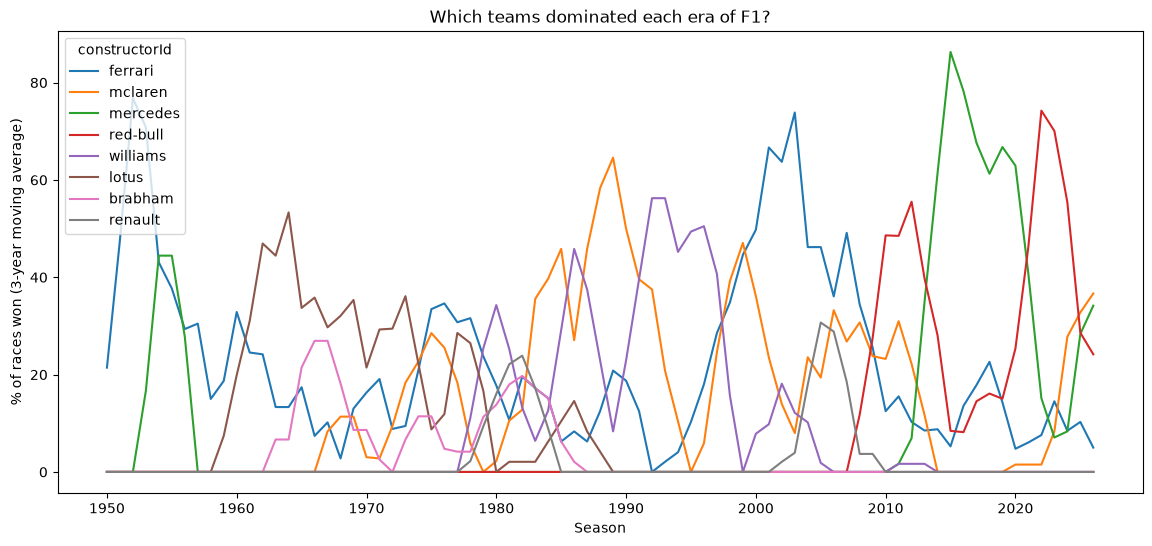

In [30]:
import matplotlib.pyplot as plt

ax = smooth[top_teams].plot(figsize=(14, 6))
ax.set_title("Which teams dominated each era of F1?")
ax.set_xlabel("Season")
ax.set_ylabel("% of races won (3-year moving average)")
plt.show()

In [31]:
pivot.loc[2026].sort_values(ascending=False).head()

constructorId
mercedes      60.0
mclaren       15.0
red-bull      15.0
ferrari       10.0
alphatauri     0.0
Name: 2026, dtype: float64

In [32]:
dominant_teams = smooth.columns[smooth.max() >= 40]
dominant_teams

Index(['alfa-romeo', 'benetton', 'cooper', 'ferrari', 'lotus', 'mclaren',
       'mercedes', 'red-bull', 'tyrrell', 'williams'],
      dtype='str', name='constructorId')

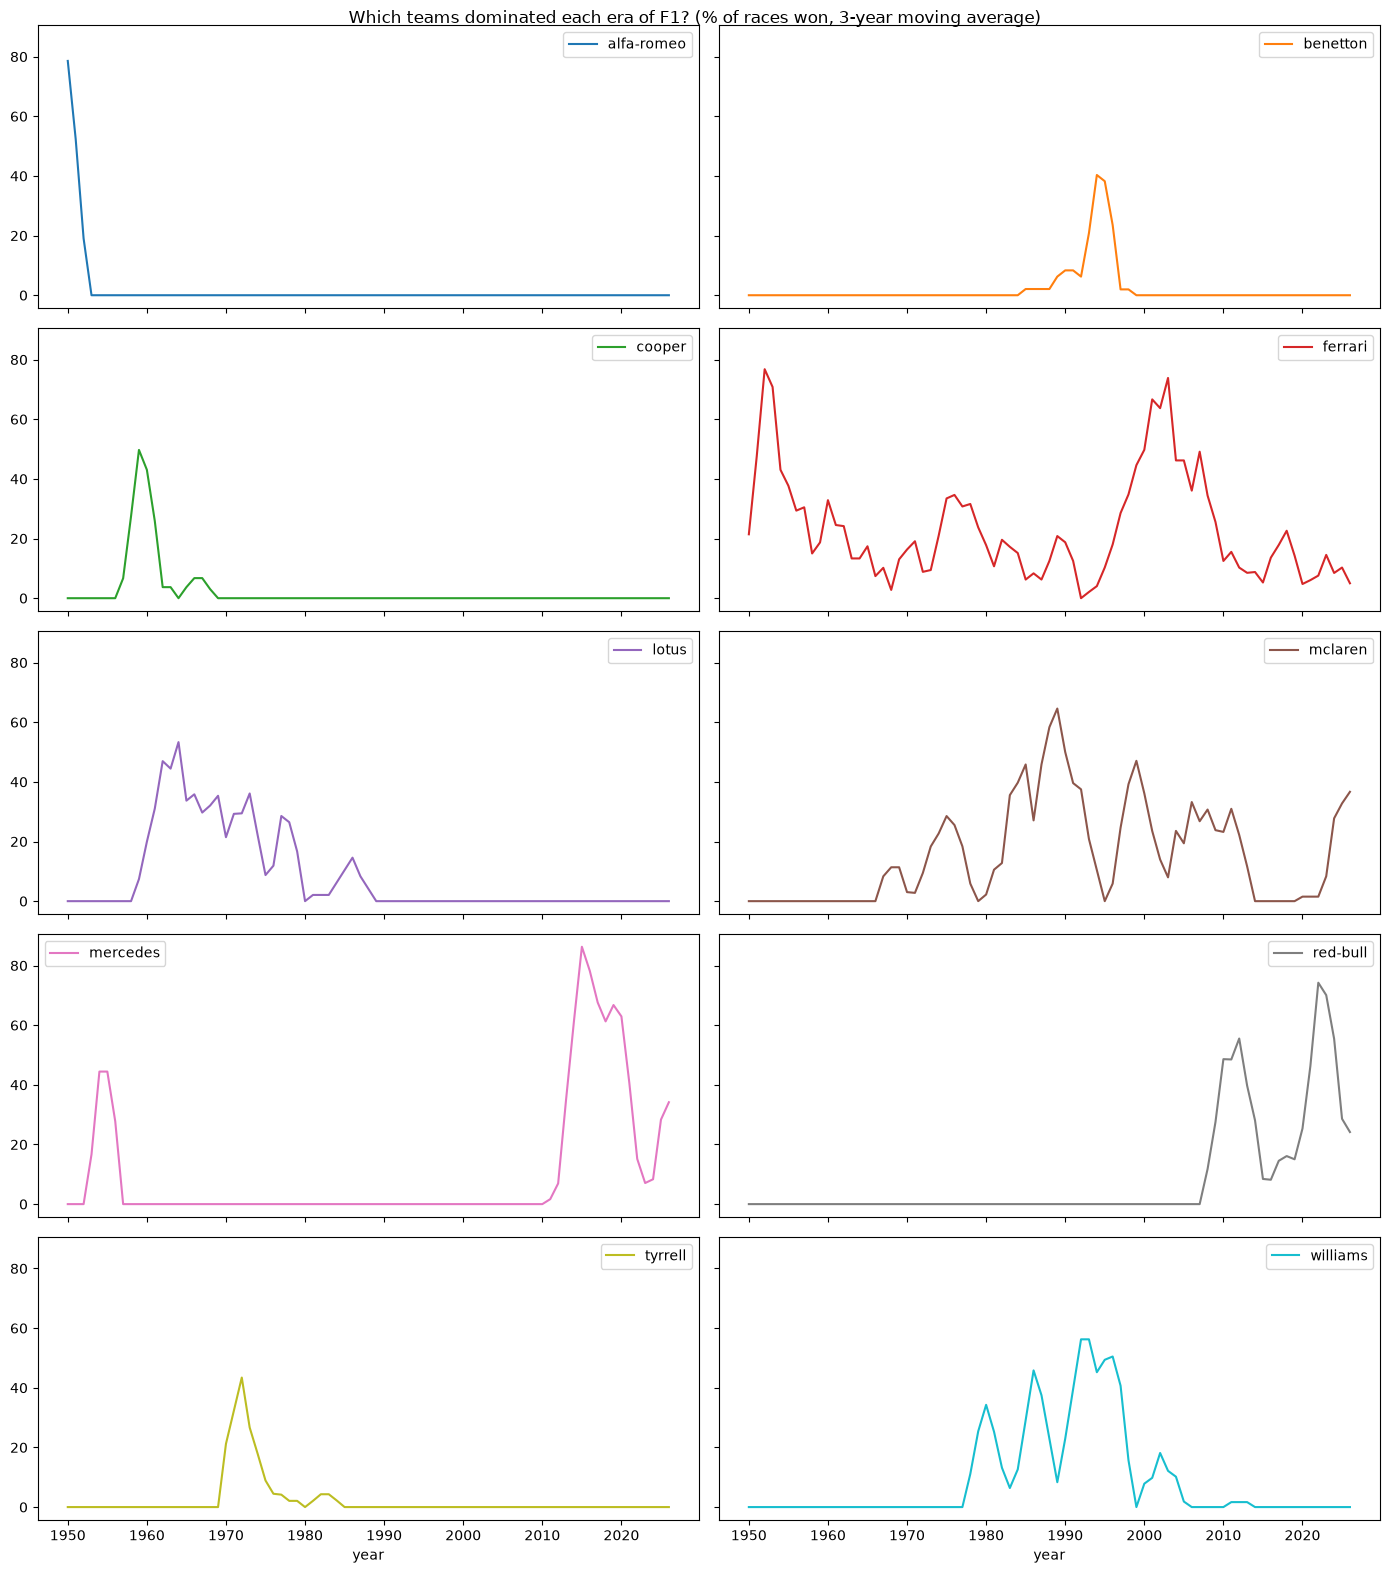

In [33]:
smooth[dominant_teams].plot(subplots=True, layout=(5, 2), figsize=(14, 16), sharex=True, sharey=True)
plt.suptitle("Which teams dominated each era of F1? (% of races won, 3-year moving average)")
plt.tight_layout()
plt.show()

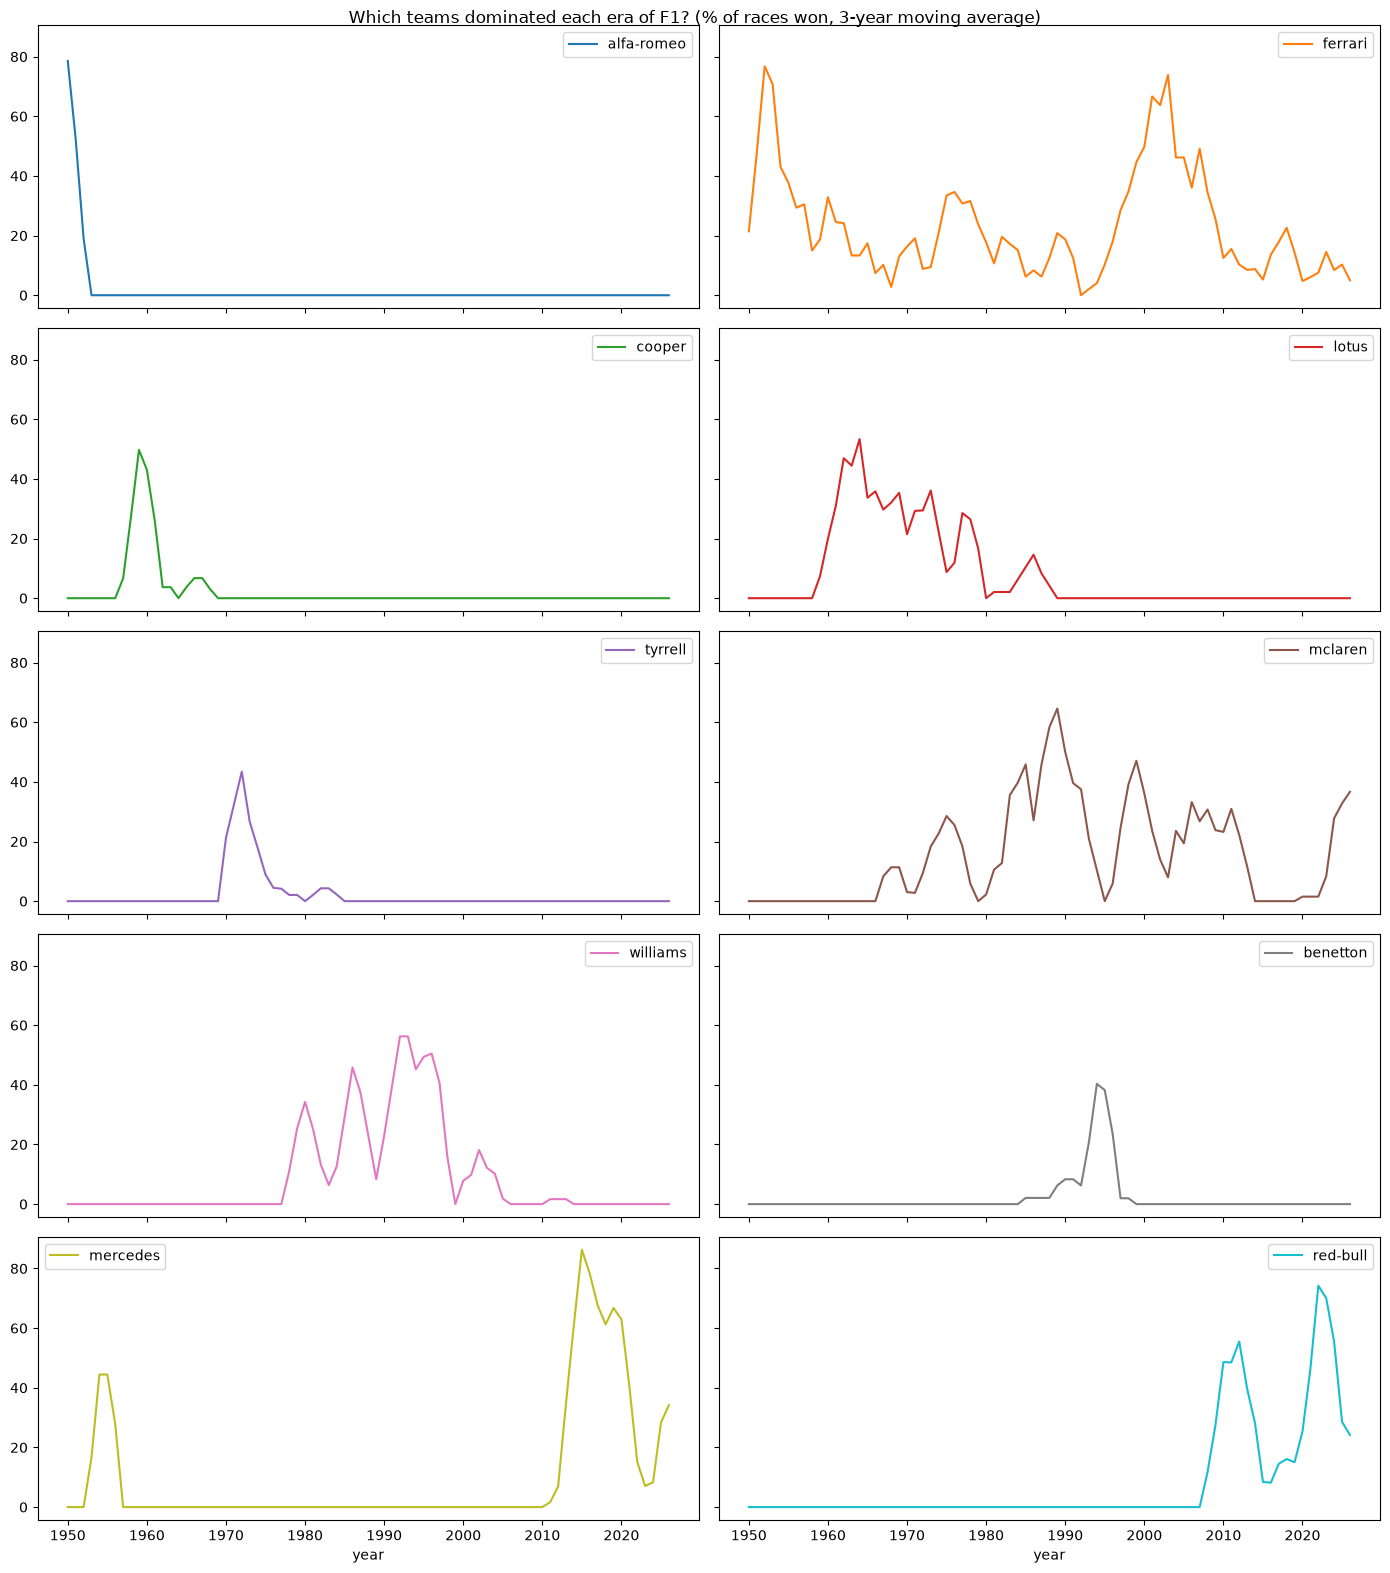

In [34]:
order = smooth[dominant_teams].idxmax().sort_values().index

smooth[order].plot(subplots=True, layout=(5, 2), figsize=(14, 16), sharex=True, sharey=True)
plt.suptitle("Which teams dominated each era of F1? (% of races won, 3-year moving average)")
plt.tight_layout()
plt.savefig("../figures/dominant_teams.png", dpi=150)
plt.show()

## Conclusions

- We can divide the results into six eras:
  - **Era 1 (1950-1960):** F1 began in 1950, and in this first era Alfa Romeo dominated 1950-51, winning every race in 1950 (6 out of 6). In 1952-53, with Alberto Ascari, Ferrari emerged as the dominant team, and after them Mercedes showed its ability to win with Juan Manuel Fangio in 1954-55. At the end of the decade, Cooper won two titles (1959-60) with Jack Brabham thanks to its revolutionary rear-engined car, a design every team copied soon after. (The 1950s Mercedes and today's Mercedes share a name but are different teams: the current one returned to F1 in 2010 and became dominant from 2014.)
  - **Era 2 (1960-1975):** Lotus emerged as the dominant team with Jim Clark, while Ferrari suffered a major setback. In the mid-1960s, Brabham had its best years, and in the early 1970s Tyrrell dominated with Jackie Stewart. In the mid-1970s, Ferrari returned strongly with Niki Lauda.
  - **Era 3 (1975-1985):** This was a fairly diverse era, with no single team standing out above the rest. Ferrari and Williams appear as the most successful teams, closely followed by McLaren, Lotus and, towards the end of the era, Renault.
  - **Era 4 (1985-2000):** The diversity disappeared and two teams took turns at the top: McLaren in the late 1980s (with Alain Prost and the wonderful Ayrton Senna) and Williams in the early 1990s. Benetton won its first titles with Michael Schumacher in 1994-95, and McLaren returned to the front in the late 1990s with Mika Häkkinen. At the end of this era, Ferrari regained its strength. Teams like Lotus and Brabham disappeared for good, never to return among the most successful teams.
  - **Era 5 (2000-2010):** In the early 2000s, Ferrari returned to the top as the most successful team, with Michael Schumacher. Williams began its definitive decline. Renault returned to the top, matching McLaren in wins, but faded again by the end of the decade. McLaren remained one of the leading teams, but Ferrari dominated the record books of this era.
  - **Era 6 (2010-today):** Red Bull improved quickly and dominated 2010-2013 with Sebastian Vettel. Mercedes then began the most dominant period in F1 history, with Lewis Hamilton. Red Bull caught up in the early 2020s with Max Verstappen, while Ferrari and McLaren remained top teams, generally well behind both. McLaren improved and won the 2025 Constructors' Championship. After a sharp decline, Mercedes is dominant again: in 2026 (provisional, 20 races) it has won 60% of the races, ahead of McLaren and Red Bull (15% each) and Ferrari (10%).
- By this measure, Mercedes 2014-2016 had the highest share of race wins in F1 history (over 85% on a 3-year average). It also won a record eight consecutive Constructors' Championships (2014-2021).
- Looking at the data from 1950 onwards, Ferrari stands out as the only team with eras of dominance in very different periods of F1. The sport has changed a lot in that time, from the rules and engines to the way cars are designed. Ferrari's ability to adapt and get back to the front after weaker seasons is a big part of what makes its long-term record so strong.
- This first simple exercise taught me that F1 teams can go years without a win and still spend every season improving the car, trying to get back to the top. To be honest, I loved my first little data deep dive. I found out that the Indy 500 once counted towards the World Championship and that two drivers could share a car and a win. That's what I'm enjoying about data analysis: the numbers give me a more objective view of the sport, and digging into the outliers leads me to stories and details I'd probably never have come across otherwise. I'm really glad I started, and I'm excited to see what I uncover next.

## Decisions and limitations

- **Source:** F1DB release v2026.20.0 (data up to the 2026 Brazilian Grand Prix), licensed under CC BY 4.0.
- **Metric: % of races won per season**, not points. Points systems and the number of races per season have changed many times, so points are not comparable across eras.
- **Indianapolis 500 excluded (1950-1960).** It counted for the World Championship, but it was a separate American race with different cars and teams. Keeping it would understate the dominance of F1 teams (e.g. Alfa Romeo in 1950: 6/6 = 100% instead of 6/7). It was filtered by Grand Prix, not by circuit, to keep the 2000-2007 United States Grands Prix held at Indianapolis.
- **Shared-car wins counted once.** In three races (1951, 1956, 1957), two drivers of the same team shared the winning car and both are credited with the win. Each race counts as one win for the team: 1,158 race wins in total.
- **Teams counted by official constructor name, not by factory.** For example, Toro Rosso and AlphaTauri are counted separately, Lotus (1958-1994) and Lotus F1 (2012-2015) are different teams, and "mercedes" covers both the 1950s works team and the current team.
- **3-year centred moving average** to show eras instead of year-to-year noise. It smooths peaks (McLaren 1988: 93.75% becomes 58.3%) and is less reliable at the edges (1950 and 2026).
- **Dominant teams = a peak of at least 40%** on the moving average. Selecting the teams with the most total wins was biased towards long-lived teams and hid short eras of dominance, such as Alfa Romeo's. The 40% threshold is a judgement call.
- **The 2026 season is incomplete**, so its values are provisional.